In [2]:
import pandas as pd, numpy as np, seaborn as sns, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn import metrics

In [4]:
df = pd.read_csv('emails.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5172 entries, 0 to 5171
Columns: 3002 entries, Email No. to Prediction
dtypes: int64(3001), str(1)
memory usage: 118.5 MB


In [6]:
df.head()

,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0


In [8]:
df.drop(columns=['Email No.'], inplace=True, errors='ignore')
df.isna().sum().sum()

0

In [10]:
df.describe()

,the,to,ect,and,for,of,a,you,hou,in,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
count,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,...,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000,5172.000000
mean,6.640565,6.188128,5.143852,3.075599,3.124710,2.627030,55.517401,2.466551,2.024362,10.600155,...,0.005027,0.012568,0.010634,0.098028,0.004254,0.006574,0.004060,0.914733,0.006961,0.290023
std,11.745009,9.534576,14.101142,6.045970,4.680522,6.229845,87.574172,4.314444,6.967878,19.281892,...,0.105788,0.199682,0.116693,0.569532,0.096252,0.138908,0.072145,2.780203,0.098086,0.453817
min,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,1.000000,0.000000,1.000000,0.000000,12.000000,0.000000,0.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,1.000000,1.000000,2.000000,1.000000,28.000000,1.000000,0.000000,5.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8.000000,7.000000,4.000000,3.000000,4.000000,2.000000,62.250000,3.000000,1.000000,12.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000
max,210.000000,132.000000,344.000000,89.000000,47.000000,77.000000,1898.000000,70.000000,167.000000,223.000000,...,4.000000,7.000000,2.000000,12.000000,3.000000,4.000000,3.000000,114.000000,4.000000,1.000000


In [11]:
X = df.iloc[:, :df.shape[1]-1]     # Independent variables
y = df.iloc[:, -1]                 # Dependent variable (0 = Not Spam, 1 = Spam)
X.shape, y.shape

((5172, 3000), (5172,))

In [14]:
y.value_counts()

Prediction
0    3672
1    1500
Name: count, dtype: int64

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=8)

In [18]:
models = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=2),
    "Linear SVM": LinearSVC(random_state=8, max_iter=900000),
    "Polynomial SVM": SVC(kernel="poly", degree=2, random_state=8),
    "RBF SVM": SVC(kernel="rbf", random_state=8),
    "Sigmoid SVM": SVC(kernel="sigmoid", random_state=8)
}

In [20]:
for name, model in models.items():
    y_pred = model.fit(X_train, y_train).predict(X_test)
    print(f"Accuracy for {name} model \t: {metrics.accuracy_score(y_test, y_pred)}")

Accuracy for K-Nearest Neighbors model 	: 0.8878865979381443
Accuracy for Linear SVM model 	: 0.979381443298969
Accuracy for Polynomial SVM model 	: 0.7615979381443299
Accuracy for RBF SVM model 	: 0.8182989690721649
Accuracy for Sigmoid SVM model 	: 0.6237113402061856


In [22]:
results = []
for name, model in models.items():
    y_pred = model.predict(X_test)
    results.append([
        name,
        metrics.accuracy_score(y_test, y_pred),
        metrics.precision_score(y_test, y_pred),
        metrics.recall_score(y_test, y_pred),
        metrics.f1_score(y_test, y_pred)
    ])

result_df = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-score'])
result_df

,Model,Accuracy,Precision,Recall,F1-score
0,K-Nearest Neighbors,0.887887,0.852792,0.743363,0.794326
1,Linear SVM,0.979381,0.968750,0.960177,0.964444
2,Polynomial SVM,0.761598,0.976744,0.185841,0.312268
3,RBF SVM,0.818299,0.920792,0.411504,0.568807
4,Sigmoid SVM,0.623711,0.333333,0.292035,0.311321


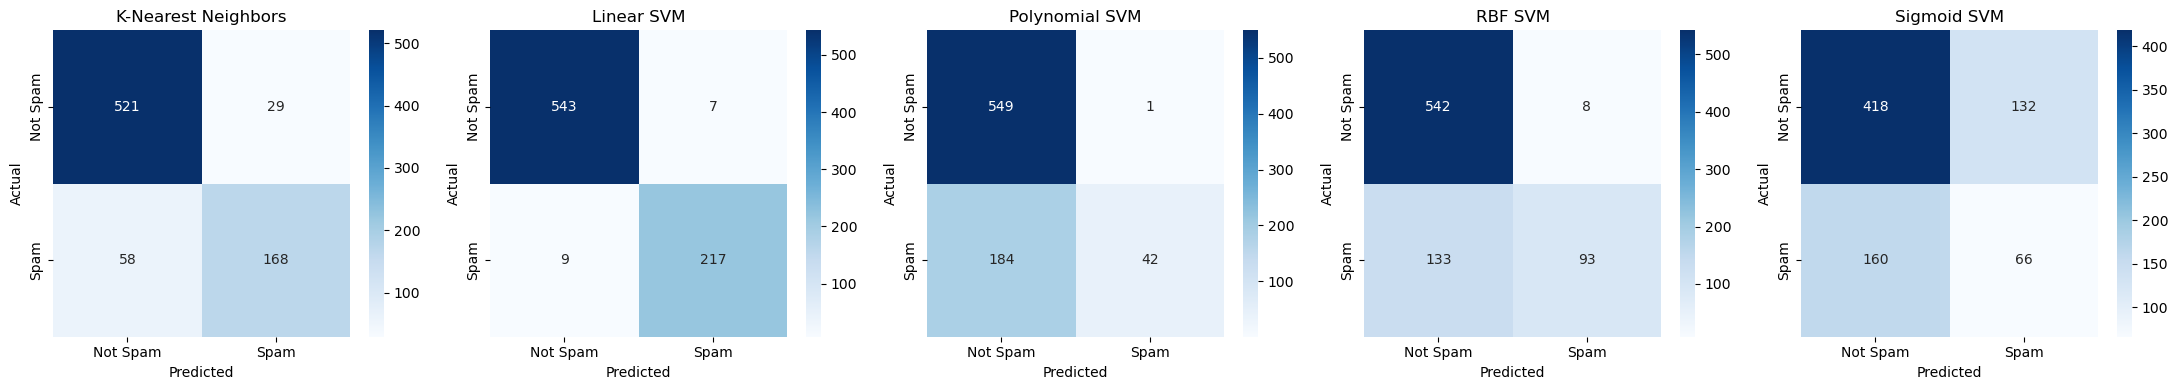

In [24]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (name, model) in zip(axes, models.items()):
    cm = metrics.confusion_matrix(y_test, model.predict(X_test))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Not Spam', 'Spam'], yticklabels=['Not Spam', 'Spam'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

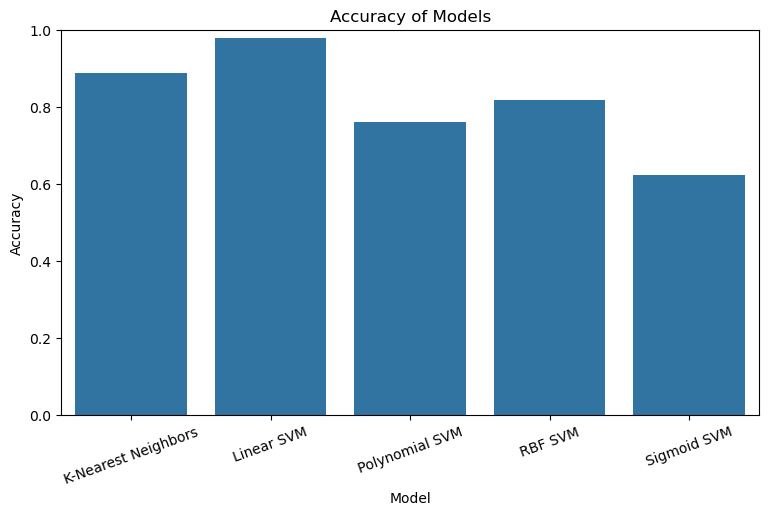

In [26]:
plt.figure(figsize=(9, 5))
sns.barplot(x='Model', y='Accuracy', data=result_df)
plt.xticks(rotation=20)
plt.ylim(0, 1)
plt.title("Accuracy of Models")
plt.show()

In [ ]:
%pip install tensorflow